We perform some basic experiments by fitting an ellipse. 

In [1]:
# First manage the imports
import numpy as np
import matplotlib.pyplot as plt

from bayes_shape_fitting.inference.likelihoods import MarginalLikelihood
from bayes_shape_fitting.inference.posterior import MarginalPosterior
from bayes_shape_fitting.inference.priors import Prior, GaussianPrior, UniformPrior
from bayes_shape_fitting.inference.samplers.map_estimation import MAPOptimizer
from bayes_shape_fitting.visualization.plotting_2d import ShapePlotter2D
from bayes_shape_fitting.inference.noise_functions import IsotropicNoise
from bayes_shape_fitting.inference.source_densitites import BetaSourceDensity, UniformSourceDensity
from bayes_shape_fitting.models.shapes.shape_examples import shape_cases
from bayes_shape_fitting.utils.sample_data import simulate_measurement

Importing bayes_shape_fitting.inference
Importing bayes_shape_fitting.models.shapes
Importing bayes_shape_fitting.utils
Importing bayes_shape_fitting.visualization


In [2]:
np.random.seed(26)

In [3]:
# first we define the shape case
case = shape_cases[1]

shape = case["shape"]
theta = case["theta"]
init_theta = case["init_params"]

In [4]:
# we define a uniform source density
source_density_true = UniformSourceDensity(n_dim = 1, fixed_params=np.array([0.2,0.4]),domain_low = shape.domain_low, domain_high = shape.domain_high, periodic = shape.periodic )

In [5]:
# the noise function is chosen to be isotropic
noise_function = IsotropicNoise(dim_param=shape.parameter_dim, dim_ambient=shape.ambient_dim, fixed_params=0.1)

In [6]:
# simulate a measurement of 100 points
measurement = simulate_measurement(shape, theta, source_density_true, noise_function, num_samples=100)

In [7]:
# for formulating a posterior, we need to define likelihood and prior
# we choose a Gaussian Mixture as source density

# let's also define a prior on the Source density
mean = np.array([0.2,0.4])  # resembels mean and variance of the gaussian
cov =  np.diag([1,0.1]) 
prior = GaussianPrior(mean=mean, cov=cov)

source_density = UniformSourceDensity(n_dim = 1, domain_low = shape.domain_low, domain_high = shape.domain_high, periodic = shape.periodic, prior = prior)

In [8]:
# then the likelihood 
likelihood = MarginalLikelihood(shape=shape, source_density=source_density, noise_function=noise_function)

In [9]:
# and the posterior
posterior = MarginalPosterior(shape=shape, measurement=measurement, likelihood=likelihood)

In [10]:
# now we define the optimizer
optimizer = MAPOptimizer(method='L-BFGS-B', verbose=True)

In [11]:
# let us define an initial guess for the source density
init_source_density = np.array([0.2, 0.43])     # mu, sigma

(<Figure size 1000x800 with 1 Axes>,
 <Axes: title={'center': 'Source Density Function'}, xlabel='Parameter t', ylabel='Density'>)

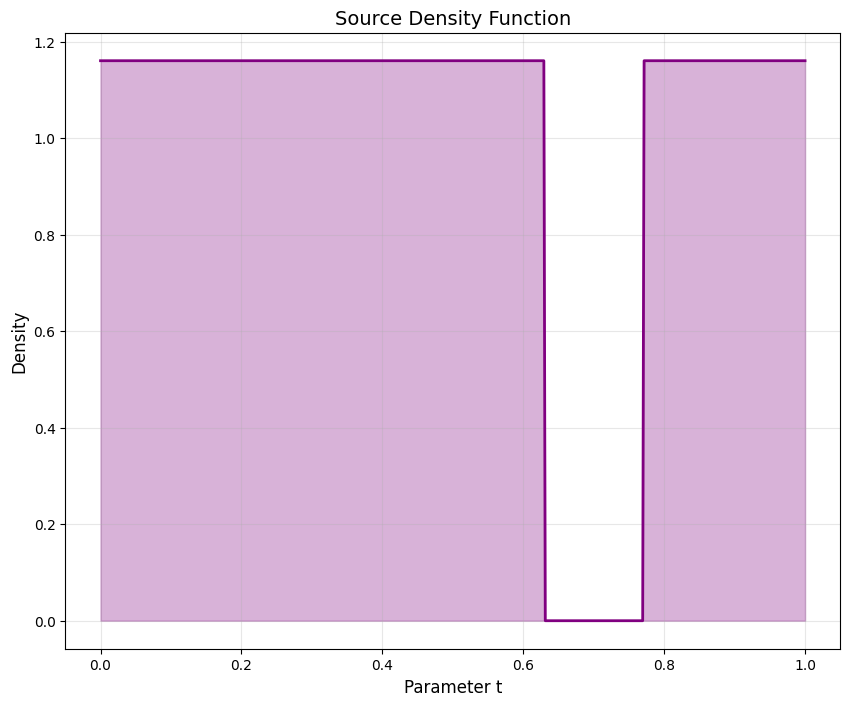

In [12]:
# Let's define a plotter and plot the initial source_density
plotter = ShapePlotter2D()
plotter.plot_source_density(shape, source_density, params=init_source_density)

In [ ]:
# perform the MAP estimation
bounds = [(0,1),(0.01,np.inf)]
result = optimizer.optimize(posterior, shape_init=init_theta, source_init=init_source_density, source_bounds=bounds)

MAP Optimization with L-BFGS-B
Initial log posterior: -1288.706403
Optimizing blocks: shape source
Number of optimized parameters: 7
Using box constraints: 7 bounds



In [ ]:
theta_map = result.theta_map[0:shape.get_n_params()]

In [ ]:
# we plot the result of the fit
fig, ax, _ = plotter.plot_shape(shape, theta, label="Ground Truth")
plotter.plot_shape(shape, theta_map, ax=ax, label="Fitted Curve", color="green")
plotter.plot_shape(shape, init_theta, ax=ax, label="Initial Fit", color="orange")
plotter.plot_observations(observations=measurement, ax=ax)

In [ ]:
# let's do the animation
from bayes_shape_fitting.visualization.animation_2d import ShapePlotterAnimations

animator = ShapePlotterAnimations()
# we need to crop the param_history to only get the shape values
param_history = [r[:5] for r in result.param_history]

# first plot the real shape
fig, ax, _ = plotter.plot_shape(shape, theta, label="Ground Truth", color = "red")
plotter.plot_observations(observations=measurement, ax=ax)
ani = animator.animate_param_history(shape, param_history, ax = ax)
ani.save("my_animation.gif", writer="pillow", fps=10)
from IPython.display import Image
Image("my_animation.gif")

In [ ]:
# let's also animate the source_density

source_params_history = [r[5:] for r in result.param_history]

plotter.plot_source_density(shape, source_density, params=source_density_true.fixed_params)

ani_source = animator.animate_source_density(shape, source_density, source_params_history)
ani_source.save("Source_density_animation.gif", writer="pillow", fps=10)
Image("Source_density_animation.gif")